# Pilot 2: adding retrieval (RAG) with PyTerrier

**Question:** in Pilot 1 the model was given the correct abstract. In a real RAG system it has to *find* the evidence first. Does weak retrieval predict wrong answers, and is it a better warning signal than the model's own confidence?

**Method**
1. Index all 1,000 expert-labelled PubMedQA abstracts with PyTerrier (BM25).
2. For each of the same 500 questions as Pilot 1, retrieve the top 3 abstracts.
3. Qwen2.5-7B-Instruct (4-bit) answers yes / no / maybe using only the retrieved abstracts.
4. Warning signals compared: (a) token probability of the answer, (b) BM25 score of the top abstract, (c) gap between the top two BM25 scores.

**Before running:** Runtime > Change runtime type > **T4 GPU**. Set `N_QUESTIONS = 20` for a quick test, then 500 (about 10 to 20 minutes). Optional: upload `pilot_results_V3.csv` from Pilot 1 (folder icon on the left) to compare the two pilots.

In [1]:
!pip -q install -U transformers accelerate bitsandbytes datasets scikit-learn python-terrier
!java -version 2>&1 | head -1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
[0.012s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## 1. Settings

In [2]:
MODEL_NAME  = "Qwen/Qwen2.5-7B-Instruct"
N_QUESTIONS = 500        # 20 for a quick test, then 500
TOP_K       = 3          # abstracts retrieved per question
SEED        = 42         # same seed as Pilot 1, so the same 500 questions
OUT_CSV     = "pilot2_rag_results.csv"
LABELS      = ["yes", "no", "maybe"]

## 2. Load the questions and the abstracts

In [3]:
from datasets import load_dataset
import random
from collections import Counter
full = load_dataset("qiaojin/PubMedQA", "pqa_labeled")["train"]   # 1,000 questions and abstracts

# the corpus = all 1,000 abstracts (the system must search among them)
corpus = {str(r["pubid"]): " ".join(r["context"]["contexts"]) for r in full}
print("Abstracts in corpus:", len(corpus))

# the same 500 questions as Pilot 1
idx = list(range(len(full)))
random.Random(SEED).shuffle(idx)
ds = full.select(idx[:N_QUESTIONS])
print(len(ds), "questions | answer mix:", Counter(ds["final_decision"]))

README.md:   0%|          | 0.00/5.19k [00:00<?, ?B/s]

pqa_labeled/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.08MB            

pqa_labeled/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Abstracts in corpus: 1000
500 questions | answer mix: Counter({'yes': 292, 'no': 168, 'maybe': 40})


## 3. Build the search index with PyTerrier (BM25)

In [4]:
import pyterrier as pt, re, pandas as pd
try:
    if not pt.java.started():
        pt.java.init()
except AttributeError:          # older PyTerrier versions
    if not pt.started():
        pt.init()

indexer = pt.IterDictIndexer("./pubmedqa_index", overwrite=True)
index_ref = indexer.index({"docno": d, "text": t} for d, t in corpus.items())

try:
    bm25 = pt.terrier.Retriever(index_ref, wmodel="BM25", num_results=TOP_K)
except AttributeError:          # older PyTerrier versions
    bm25 = pt.BatchRetrieve(index_ref, wmodel="BM25", num_results=TOP_K)

def clean(q):                   # Terrier's query parser does not like punctuation
    return re.sub(r"[^A-Za-z0-9 ]", " ", q)

topics = pd.DataFrame({"qid": [str(r["pubid"]) for r in ds],
                       "query": [clean(r["question"]) for r in ds]})
ret = bm25.transform(topics)
print(ret.head())

terrier-assemblies 5.11 jar-with-dependencies not found, downloading to /root/.pyterrier...


https://repo1.maven.org/maven2/org/terrier/terrier-assemblies/5.11/terrier-assemblies-5.11-jar-with-dependenci…

Done
terrier-python-helper 0.0.8 jar not found, downloading to /root/.pyterrier...


https://repo1.maven.org/maven2/org/terrier/terrier-python-helper/0.0.8/terrier-python-helper-0.0.8.jar:   0%| …

Done


Java started and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


        qid                                              query  docid  \
0  10922093  Does open access endoscopy close the door to a...    776   
1  10922093  Does open access endoscopy close the door to a...    277   
2  10922093  Does open access endoscopy close the door to a...    939   
3  15388567  Are sports medicine journals relevant and appl...    507   
4  15388567  Are sports medicine journals relevant and appl...    816   

      docno  rank      score  
0  10922093     0  30.379001  
1  22683044     1  18.838714  
2  21592383     2  16.675357  
3  15388567     0  44.280794  
4  24340838     1  25.199029  


In [5]:
# retrieval quality: how often is the question's own abstract found?
gold = {str(r["pubid"]) for r in ds}
hits = {}
for qid, g in ret.groupby("qid"):
    g = g.sort_values("rank")
    docs, scores = list(g.docno), list(g.score)
    hits[qid] = {"docs": docs, "scores": scores}
top1 = sum(hits.get(q, {"docs": [None]})["docs"][0] == q for q in gold) / len(gold)
topk = sum(q in hits.get(q, {"docs": []})["docs"] for q in gold) / len(gold)
print(f"Own abstract ranked first: {top1:.1%} | in top {TOP_K}: {topk:.1%}")
for q in gold:                  # a question with no search results gets an empty entry
    hits.setdefault(q, {"docs": [], "scores": []})

Own abstract ranked first: 95.2% | in top 3: 98.2%


## 4. Load the model (4-bit)

In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto")
model.eval()

LABEL_TOKEN_IDS = {}
for lab in LABELS:
    ids = set()
    for v in [lab, lab.capitalize(), " " + lab, " " + lab.capitalize()]:
        ids.add(tok.encode(v, add_special_tokens=False)[0])
    LABEL_TOKEN_IDS[lab] = sorted(ids)
print("Loaded", MODEL_NAME)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-7B-Instruct


## 5. Prompt with the retrieved abstracts (same wording as Pilot 1)

In [7]:
def build_prompt(question, docnos):
    context = "\n\n".join(f"Abstract {i+1}:\n{corpus[d]}" for i, d in enumerate(docnos))
    user = context + "\n\nQuestion: " + question + "\nAnswer with exactly one word: yes, no, or maybe."
    msgs = [{"role": "system", "content": "You are a biomedical expert. Read the abstracts and answer the question."},
            {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + "Answer:"

# quick check on 3 questions
for r in ds.select(range(3)):
    h = hits[str(r["pubid"])]
    inputs = tok(build_prompt(r["question"], h["docs"]), return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=3, do_sample=False, pad_token_id=tok.eos_token_id)
    print(repr(tok.decode(out[0, inputs["input_ids"].shape[1]:])), "| correct:", r["final_decision"],
          "| own abstract retrieved:", str(r["pubid"]) in h["docs"])

' yes<|im_end|>' | correct: yes | own abstract retrieved: True
' Maybe\n\nExplanation' | correct: no | own abstract retrieved: True
' Yes\n\nThe' | correct: no | own abstract retrieved: True


## 6. Run all questions
Safe to re-run: questions already in the CSV are skipped.

In [8]:
import os
from tqdm.auto import tqdm
done = set(pd.read_csv(OUT_CSV)["pubid"].astype(str)) if os.path.exists(OUT_CSV) else set()

@torch.no_grad()
def ask(r):
    pid = str(r["pubid"]); h = hits[pid]
    inputs = tok(build_prompt(r["question"], h["docs"]), return_tensors="pt").to(model.device)
    probs = torch.softmax(model(**inputs).logits[0, -1].float(), dim=-1)
    p = {lab: probs[LABEL_TOKEN_IDS[lab]].sum().item() for lab in LABELS}
    s = sum(p.values()); p = {k: v / s for k, v in p.items()}
    ans = max(p, key=p.get)
    sc = h["scores"] + [0.0] * (2 - len(h["scores"]))
    return {"pubid": pid, "question": r["question"], "gold": r["final_decision"], "answer": ans,
            "p_yes": p["yes"], "p_no": p["no"], "p_maybe": p["maybe"], "token_conf": p[ans],
            "own_abstract_top1": bool(h["docs"]) and h["docs"][0] == pid, "own_abstract_topk": pid in h["docs"],
            "bm25_top1": sc[0], "bm25_gap": sc[0] - sc[1], "retrieved": "|".join(h["docs"])}

buf = []
for r in tqdm(ds):
    if str(r["pubid"]) in done:
        continue
    buf.append(ask(r))
    if len(buf) >= 20:
        pd.DataFrame(buf).to_csv(OUT_CSV, mode="a", header=not os.path.exists(OUT_CSV), index=False); buf = []
if buf:
    pd.DataFrame(buf).to_csv(OUT_CSV, mode="a", header=not os.path.exists(OUT_CSV), index=False)
print("Finished")

  0%|          | 0/500 [00:00<?, ?it/s]

Finished


## 7. Results

In [9]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
df = pd.read_csv(OUT_CSV).drop_duplicates("pubid")
df["wrong"] = (df.answer != df.gold).astype(int)

print(f"Questions: {len(df)}")
print(f"Own abstract ranked first: {df.own_abstract_top1.mean():.1%} | in top {TOP_K}: {df.own_abstract_topk.mean():.1%}")
print(f"Accuracy with retrieval (RAG): {1 - df.wrong.mean():.1%}")
print(f"  when own abstract ranked first: {1 - df[df.own_abstract_top1].wrong.mean():.1%} (n={df.own_abstract_top1.sum()})")
if (~df.own_abstract_top1).sum() > 0:
    print(f"  when it was not:                {1 - df[~df.own_abstract_top1].wrong.mean():.1%} (n={(~df.own_abstract_top1).sum()})")

committed = df[df.answer != "maybe"]
print(f"When it answered yes or no: {1 - committed.wrong.mean():.1%} correct ({(committed.wrong == 0).sum()} of {len(committed)})")
print(f"'maybe' answers: {(df.answer == 'maybe').sum()} (needed: {(df.gold == 'maybe').sum()}), correct: {((df.answer == 'maybe') & (df.gold == 'maybe')).sum()}")

print("\nAUROC for spotting wrong answers (0.5 = coin toss, 1.0 = perfect):")
signals = {"Token probability": 1 - df.token_conf,
           "BM25 top score (low = warning)": -df.bm25_top1,
           "BM25 gap top1-top2 (low = warning)": -df.bm25_gap}
for name, s in signals.items():
    print(f"  {name:38s} {roc_auc_score(df.wrong, s):.3f}")
print()
print(pd.crosstab(df.gold, df.answer, margins=True))

Questions: 500
Own abstract ranked first: 95.2% | in top 3: 98.2%
Accuracy with retrieval (RAG): 51.2%
  when own abstract ranked first: 52.3% (n=476)
  when it was not:                29.2% (n=24)
When it answered yes or no: 84.6% correct (231 of 273)
'maybe' answers: 227 (needed: 40), correct: 25

AUROC for spotting wrong answers (0.5 = coin toss, 1.0 = perfect):
  Token probability                      0.678
  BM25 top score (low = warning)         0.568
  BM25 gap top1-top2 (low = warning)     0.572

answer  maybe  no  yes  All
gold                       
maybe      25   1   14   40
no        103  46   19  168
yes        99   8  185  292
All       227  55  218  500


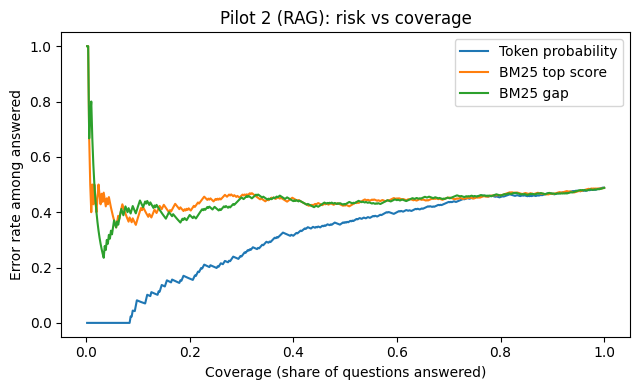

In [10]:
# Risk vs coverage for each signal
def risk_coverage(score_high_is_safe, wrong):
    order = np.argsort(-score_high_is_safe.values)
    w = wrong.values[order]; n = np.arange(1, len(w) + 1)
    return n / len(w), np.cumsum(w) / n

fig, ax = plt.subplots(figsize=(6.5, 4))
for name, safe in [("Token probability", df.token_conf), ("BM25 top score", df.bm25_top1), ("BM25 gap", df.bm25_gap)]:
    cov, risk = risk_coverage(safe, df.wrong)
    ax.plot(cov, risk, label=name)
ax.set_xlabel("Coverage (share of questions answered)"); ax.set_ylabel("Error rate among answered")
ax.set_title("Pilot 2 (RAG): risk vs coverage"); ax.legend()
plt.tight_layout(); plt.savefig("pilot2_plots.png", dpi=150); plt.show()

In [11]:
# Optional: compare with Pilot 1 (correct abstract given). Upload pilot_results_V3.csv first.
if os.path.exists("pilot_results_V3.csv"):
    p1 = pd.read_csv("pilot_results_V3.csv").drop_duplicates("pubid")
    p1["pubid"] = p1.pubid.astype(str); df["pubid"] = df.pubid.astype(str)
    m = df.merge(p1[["pubid", "greedy_answer"]], on="pubid")
    print(f"Same {len(m)} questions:")
    print(f"  Pilot 1, correct abstract given: {(m.greedy_answer == m.gold).mean():.1%}")
    print(f"  Pilot 2, abstracts retrieved:    {(m.answer == m.gold).mean():.1%}")
else:
    print("pilot_results_V3.csv not uploaded; skipping comparison")

pilot_results_V3.csv not uploaded; skipping comparison


In [12]:
# Confident AND wrong
for _, r in df[df.wrong == 1].sort_values("token_conf", ascending=False).head(5).iterrows():
    print(f"[{r.token_conf:.0%} sure] said {r.answer}, correct {r.gold}, own abstract top-1: {r.own_abstract_top1} | {r.question}")

[100% sure] said yes, correct no, own abstract top-1: True | Does Viral Co-Infection Influence the Severity of Acute Respiratory Infection in Children?
[100% sure] said yes, correct no, own abstract top-1: True | Should temperature be monitorized during kidney allograft preservation?
[100% sure] said yes, correct no, own abstract top-1: True | Are income-related differences in active travel associated with physical environmental characteristics?
[100% sure] said yes, correct maybe, own abstract top-1: True | Do emergency medical services professionals think they should participate in disease prevention?
[100% sure] said maybe, correct no, own abstract top-1: True | Chemoradiotherapy in the management of locally advanced squamous cell carcinoma esophagus: is surgical resection required?


## 8. Summary of results

Same 500 PubMedQA questions as Pilot 1, Qwen2.5-7B-Instruct (4-bit), top 3 abstracts retrieved with PyTerrier BM25 from all 1,000 abstracts.

- The question's own abstract was ranked first 95.2% of the time (in top 3: 98.2%).
- Accuracy: 51.2% (Pilot 1, with the correct abstract given: 46.2%).
- When retrieval missed the right abstract (24 questions), accuracy fell to 29.2%.
- When the model answered yes or no, it was right 84.6% of the time (231 of 273).
- It answered "maybe" 227 times when only 40 questions needed it; 25 were correct.
- AUROC for spotting wrong answers: 0.68 (token probability), 0.57 (BM25 top score), 0.57 (BM25 gap).

**Takeaway:** retrieval scores alone were weak warnings here, probably because search in a 1,000-abstract corpus is easy. The model's confidence was a better warning with retrieval than without, but still far from reliable, and errors were concentrated where the evidence was missing.

**Limits:** small corpus, one model, one prompt, 4-bit compression. Why accuracy rose with three abstracts is not yet clear; the prompt wording also changed slightly.